In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('processed_spotify_data.csv')
print(f"Размер датасета: {df.shape}")

y = df['stream_count']

X = df.drop(columns=['stream_count', 'log_stream_count'], errors='ignore')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nX_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

Размер датасета: (50000, 122)

X_train: (40000, 120)
X_test:  (10000, 120)
y_train: (40000,)
y_test:  (10000,)


In [34]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_test = linear_model.predict(X_test)

print("Модель обучена!")
print(f"Пример реального значения: {y_test.iloc[0]:,.2f}")
print(f"Пример предсказания: {y_pred_test[0]:,.2f}")

Модель обучена!
Пример реального значения: 6,504.00
Пример предсказания: 58,548.09


In [35]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error

MSE = mean_squared_error(y_test, y_pred_test)
RMSE = root_mean_squared_error(y_test, y_pred_test)
MAE = mean_absolute_error(y_test, y_pred_test)

print(f"MSE: {MSE:,.2f}")
print(f"RMSE: {RMSE:,.2f}")
print(f"MAE: {MAE:,.2f}")

MSE: 197,013,817,824.52
RMSE: 443,862.39
MAE: 117,356.04


In [36]:
import numpy as np
from sklearn.metrics import root_mean_squared_error

y_train_log = np.log1p(y_train)   # log(1 + x), безопасно для нулей
y_test_log = np.log1p(y_test)

log_model = LinearRegression()
log_model.fit(X_train, y_train_log)

y_pred_log = log_model.predict(X_test)

RMSE_log = root_mean_squared_error(y_test_log, y_pred_log)
print(f"RMSE (лог-масштаб): {RMSE_log:.4f}")
print(f"Среднее log(stream_count): {y_train_log.mean():.4f}")
print(f"Стандартное отклонение: {y_train_log.std():.4f}")

RMSE (лог-масштаб): 0.8028
Среднее log(stream_count): 9.8403
Стандартное отклонение: 1.7933


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

y_cls = df['is_explicit_bool']
X_cls = df.drop(
    columns=['is_explicit_bool', 'explicit', 'stream_count', 'log_stream_count'],
    errors='ignore'
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_cls_scaled = scaler.fit_transform(X_train_cls)
X_test_cls_scaled = scaler.transform(X_test_cls)

logreg_model = LogisticRegression(max_iter=1000, class_weight='balanced')
logreg_model.fit(X_train_cls_scaled, y_train_cls)

y_pred_cls = logreg_model.predict(X_test_cls_scaled)

print("Модель классификации обучена!")
print(f"Пример реального класса: {y_test_cls.iloc[0]}")
print(f"Пример предсказания: {y_pred_cls[0]}")

Модель классификации обучена!
Пример реального класса: False
Пример предсказания: False


Accuracy: 0.5073

Confusion Matrix:
[[3866 3583]
 [1344 1207]]


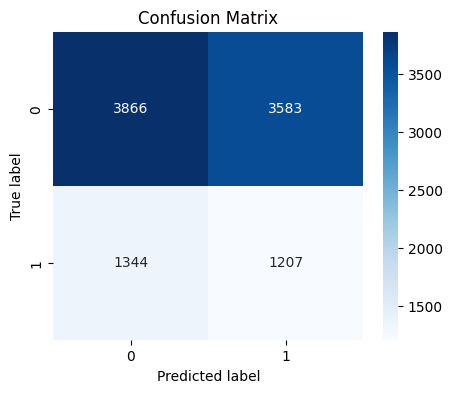


Classification Report:
              precision    recall  f1-score   support

       False       0.74      0.52      0.61      7449
        True       0.25      0.47      0.33      2551

    accuracy                           0.51     10000
   macro avg       0.50      0.50      0.47     10000
weighted avg       0.62      0.51      0.54     10000



In [49]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test_cls, y_pred_cls)
print(f"Accuracy: {accuracy:.4f}")

cm = confusion_matrix(y_test_cls, y_pred_cls)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_cls))

Распределение классов популярности:
popularity_class
Low          28449
Medium       21304
Very High      247
Name: count, dtype: int64

=== Logistic Regression (popularity) ===
Accuracy: 0.7079
              precision    recall  f1-score   support

         Low       0.71      0.81      0.76      5690
      Medium       0.69      0.56      0.62      4261
   Very High       0.96      0.88      0.91        49

    accuracy                           0.71     10000
   macro avg       0.79      0.75      0.77     10000
weighted avg       0.71      0.71      0.70     10000



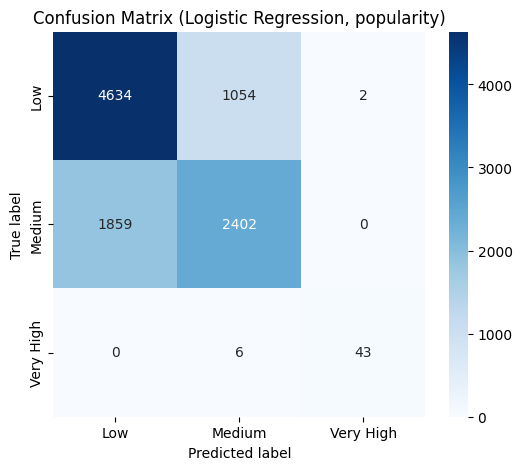

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

df['popularity_class'] = 'Low'
if 'popularity_category_Medium' in df.columns:
    df.loc[df['popularity_category_Medium'] == True, 'popularity_class'] = 'Medium'
if 'popularity_category_Very High' in df.columns:
    df.loc[df['popularity_category_Very High'] == True, 'popularity_class'] = 'Very High'

print("Распределение классов популярности:")
print(df['popularity_class'].value_counts())

y_pop = df['popularity_class']
columns_to_drop = [
    'popularity_class',
    'popularity_category_Low', 'popularity_category_Medium', 'popularity_category_Very High',
    'is_explicit_bool', 'explicit',
    'stream_count', 'log_stream_count'
]
X_pop = df.drop(columns=columns_to_drop, errors='ignore')

X_train_pop, X_test_pop, y_train_pop, y_test_pop = train_test_split(
    X_pop, y_pop, test_size=0.2, random_state=42, stratify=y_pop
)

scaler_pop = StandardScaler()
X_train_pop_scaled = scaler_pop.fit_transform(X_train_pop)
X_test_pop_scaled = scaler_pop.transform(X_test_pop)

logreg_pop = LogisticRegression(max_iter=1000)
logreg_pop.fit(X_train_pop_scaled, y_train_pop)
y_pred_pop = logreg_pop.predict(X_test_pop_scaled)

accuracy_pop = accuracy_score(y_test_pop, y_pred_pop)
print(f"\n=== Logistic Regression (popularity) ===")
print(f"Accuracy: {accuracy_pop:.4f}")
print(classification_report(y_test_pop, y_pred_pop))

cm_pop = confusion_matrix(y_test_pop, y_pred_pop)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_pop, annot=True, fmt='d', cmap='Blues',
            xticklabels=logreg_pop.classes_, yticklabels=logreg_pop.classes_)
plt.title('Confusion Matrix (Logistic Regression, popularity)')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()